# Quantum CNN (local)
Runs on the Aer simulator. Set `USE_IBM_HARDWARE = True` to run on IBM hardware (needs IBM_API_KEY and IBM_CRN in .env)

## Settings

In [1]:
USE_IBM_HARDWARE = False

MONTHS = 3

N_TRAIN = 1000
N_TEST = None              # None = every test row

# COBYLA always does at least 137 here (weights + 2)
MAXITER = 400
SEED = 12345

PRECISION = 'single'       # float32

FEATURES = ['return', 'Lag 1', 'Lag 2', 'Lag 3', 'Lag 5',
            'volatility 5', 'volatility 10', 'volatility 20', 'volatility 30',
            'SMA 10', 'SMA 20', 'SMA 30', 'SMA 50', 'id', 'volume']
NUM_QUBITS = 16            # 15 features + 1 empty qubit

## Imports

In [2]:
import os
import time
import numpy as np
import pandas as pd
import psutil
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score

from qiskit import QuantumCircuit as QC
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import z_feature_map
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.algorithms import NeuralNetworkRegressor
from qiskit_machine_learning.neural_networks import EstimatorQNN

load_dotenv()
algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)

## Data

In [3]:
from Validation import chronological_split, score

if os.path.exists('data/dataset_3y.parquet'):
    df = pd.read_parquet('data/dataset_3y.parquet')
    df = df[df['date'] > df['date'].max() - pd.DateOffset(months=MONTHS)]
else:
    from Data_Frame_10y import build_dataset, wikipedia_tickers
    df = build_dataset(months=MONTHS, tickers=wikipedia_tickers())[0]

train, test = chronological_split(df)
x_train, y_train = train[FEATURES], train['future return']
x_test, y_test = test[FEATURES], test['future return']
print(f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}, {df['ticker'].nunique()} stocks")
print(f"train rows: {len(x_train):,}   test rows: {len(x_test):,}")

2026-07-30 to 2026-10-29, 502 stocks
train rows: 26,079   test rows: 6,526


## Subsample and scale

In [4]:
train_idx = rng.choice(len(x_train), size=min(N_TRAIN, len(x_train)), replace=False)
if N_TEST is None:
    test_idx = np.arange(len(x_test))
else:
    test_idx = rng.choice(len(x_test), size=min(N_TEST, len(x_test)), replace=False)

x_train_sub = x_train.iloc[train_idx].to_numpy(dtype=np.float32)
x_test_sub = x_test.iloc[test_idx].to_numpy(dtype=np.float32)
y_train_sub = y_train.iloc[train_idx].to_numpy(dtype=np.float32)
y_test_sub = y_test.iloc[test_idx].to_numpy(dtype=np.float32)

scaler = MinMaxScaler(feature_range=(0, np.pi))
x_train_reduced = scaler.fit_transform(x_train_sub)
x_test_reduced = np.clip(scaler.transform(x_test_sub), 0, np.pi)

# pad to 16 qubits
pad = NUM_QUBITS - len(FEATURES)
x_train_reduced = np.hstack([x_train_reduced, np.zeros((len(x_train_reduced), pad), dtype=np.float32)])
x_test_reduced = np.hstack([x_test_reduced, np.zeros((len(x_test_reduced), pad), dtype=np.float32)])

# <Z> is between -1 and 1
scale_factor = np.abs(y_train_sub).max()
y_train_scaled = y_train_sub / scale_factor
print(x_train_reduced.shape, x_test_reduced.shape, x_train_reduced.dtype)

(1000, 16) (6526, 16) float32


## QCNN layers

In [5]:
def conv_circuit(params):
    target = QC(2)
    target.rz(-np.pi / 2, 1)
    target.cx(1, 0)
    target.rz(params[0], 0)
    target.ry(params[1], 1)
    target.cx(0, 1)
    target.ry(params[2], 1)
    target.cx(1, 0)
    target.rz(np.pi / 2, 0)
    return target


def conv_layer(num_qubits, param_prefix):
    qc = QC(num_qubits, name="Convolutional Layer")
    qubits = list(range(num_qubits))
    param_index = 0
    params = ParameterVector(param_prefix, length=num_qubits * 3)
    for q1, q2 in zip(qubits[0::2], qubits[1::2]):
        qc = qc.compose(conv_circuit(params[param_index:param_index + 3]), [q1, q2])
        qc.barrier()
        param_index += 3
    for q1, q2 in zip(qubits[1::2], qubits[2::2] + [0]):
        qc = qc.compose(conv_circuit(params[param_index:param_index + 3]), [q1, q2])
        qc.barrier()
        param_index += 3
    qc_inst = qc.to_instruction()
    qc = QC(num_qubits)
    qc.append(qc_inst, qubits)
    return qc


def pool_circuit(params):
    target = QC(2)
    target.rz(-np.pi / 2, 1)
    target.cx(1, 0)
    target.rz(params[0], 0)
    target.ry(params[1], 1)
    target.cx(0, 1)
    target.ry(params[2], 1)
    return target


def pool_layer(sources, sinks, param_prefix):
    num_qubits = len(sources) + len(sinks)
    qc = QC(num_qubits, name="Pooling Layer")
    param_index = 0
    params = ParameterVector(param_prefix, length=num_qubits // 2 * 3)
    for source, sink in zip(sources, sinks):
        qc = qc.compose(pool_circuit(params[param_index:param_index + 3]), [source, sink])
        qc.barrier()
        param_index += 3
    qc_inst = qc.to_instruction()
    qc = QC(num_qubits)
    qc.append(qc_inst, range(num_qubits))
    return qc

## Build the circuit

In [6]:
feature_map = z_feature_map(NUM_QUBITS)

ansatz = QC(NUM_QUBITS, name="QCNN")
ansatz.compose(conv_layer(16, "c1"), list(range(16)), inplace=True)
ansatz.compose(pool_layer(list(range(0, 8)), list(range(8, 16)), "p1"), list(range(16)), inplace=True)
ansatz.compose(conv_layer(8, "c2"), list(range(8, 16)), inplace=True)
ansatz.compose(pool_layer(list(range(0, 4)), list(range(4, 8)), "p2"), list(range(8, 16)), inplace=True)
ansatz.compose(conv_layer(4, "c3"), list(range(12, 16)), inplace=True)
ansatz.compose(pool_layer(list(range(0, 2)), list(range(2, 4)), "p3"), list(range(12, 16)), inplace=True)
ansatz.compose(conv_layer(2, "c4"), list(range(14, 16)), inplace=True)
ansatz.compose(pool_layer(list(range(0, 1)), list(range(1, 2)), "p4"), list(range(14, 16)), inplace=True)

circuit = QC(NUM_QUBITS)
circuit.compose(feature_map, range(NUM_QUBITS), inplace=True)
circuit.compose(ansatz, range(NUM_QUBITS), inplace=True)

observable = SparsePauliOp.from_list([("Z" + "I" * (NUM_QUBITS - 1), 1)])
print(f"{ansatz.num_parameters} trainable weights")

135 trainable weights


## Backend

In [7]:
if USE_IBM_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as RuntimeEstimator
    from qiskit.transpiler import generate_preset_pass_manager

    service = QiskitRuntimeService(
        channel="ibm_quantum_platform",
        token=os.environ["IBM_API_KEY"],
        instance=os.environ["IBM_CRN"],
    )
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=NUM_QUBITS)
    print("Running on", backend.name)
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    qnn_circuit = pm.run(circuit)
    qnn_observable = observable.apply_layout(qnn_circuit.layout)
    estimator = RuntimeEstimator(mode=backend)
    qnn_precision = 0.015625
else:
    try:
        from qiskit_aer.primitives import EstimatorV2 as AerEstimator
        # rows run in parallel instead of splitting up each one, ~3x faster
        estimator = AerEstimator(options={'backend_options': {'precision': PRECISION,
                                                              'statevector_parallel_threshold': NUM_QUBITS + 1,
                                                              'max_parallel_experiments': 0}})
        print(f"Running on local Aer simulator ({PRECISION} precision)")
    except ImportError:
        from qiskit.primitives import StatevectorEstimator
        estimator = StatevectorEstimator()
        print("Running on local Statevector simulator")
    from qiskit import transpile
    qnn_circuit = transpile(circuit, basis_gates=["h", "p", "rz", "ry", "cx"], optimization_level=1)
    qnn_observable = observable
    # 0 = exact, the default adds random noise
    qnn_precision = 0.0

qnn = EstimatorQNN(
    circuit=qnn_circuit,
    observables=qnn_observable,
    input_params=feature_map.parameters,
    weight_params=ansatz.parameters,
    estimator=estimator,
    default_precision=qnn_precision,
)

Running on local Aer simulator (single precision)


## Train

iteration 10  loss 0.02148  0.8 min


iteration 20  loss 0.01798  1.6 min


iteration 30  loss 0.01700  2.4 min


iteration 40  loss 0.01649  3.2 min


iteration 50  loss 0.01639  4.0 min


iteration 60  loss 0.01668  4.8 min


... (31 outputs left out)

iteration 380  loss 0.01590  373.4 min


iteration 390  loss 0.01587  375.1 min


iteration 400  loss 0.01600  377.7 min


training took 377.7 min, 400 iterations, peak RAM 0.81 GB


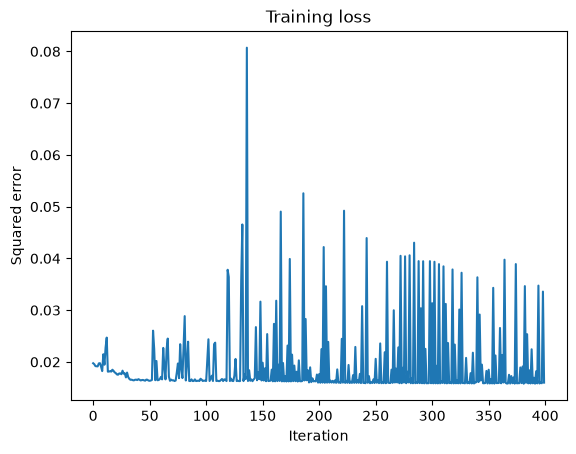

In [8]:
losses = []

def callback(weights, loss):
    losses.append(loss)
    if len(losses) % 10 == 0:
        print(f"iteration {len(losses)}  loss {loss:.5f}  {(time.time() - start) / 60:.1f} min", flush=True)

def peak_ram_gb():
    info = psutil.Process().memory_info()
    if hasattr(info, 'peak_wset'):  # windows
        return info.peak_wset / 1e9
    import resource                 # linux, in KB
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6

regressor = NeuralNetworkRegressor(
    neural_network=qnn,
    optimizer=COBYLA(maxiter=MAXITER),
    loss="squared_error",
    callback=callback,
)

start = time.time()
regressor.fit(x_train_reduced, y_train_scaled)
print(f"training took {(time.time() - start) / 60:.1f} min, {len(losses)} iterations, peak RAM {peak_ram_gb():.2f} GB")

plt.plot(losses)
plt.title("Training loss")
plt.xlabel("Iteration")
plt.ylabel("Squared error")
plt.show()

## Test

Train R²:                  0.0061
Test R²:                   -0.0272
Directional accuracy:      0.4824
Always-up baseline:        0.5541
Cross-sectional accuracy:  0.4876
IC mean:                   -0.0282


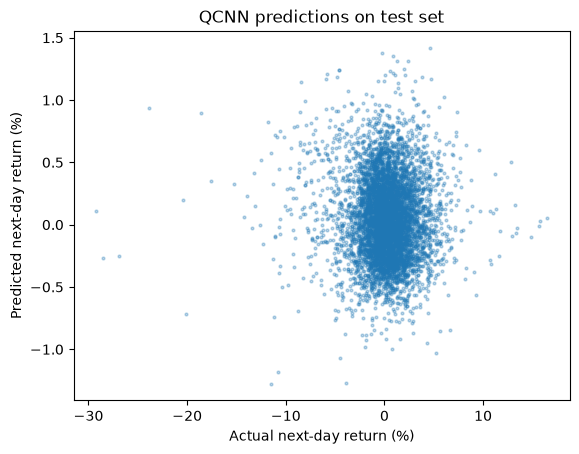

In [9]:
pred = regressor.predict(x_test_reduced).ravel() * scale_factor
train_pred = regressor.predict(x_train_reduced).ravel() * scale_factor

results = test.iloc[test_idx][['date', 'ticker', 'future return']].assign(prediction=pred)
scores = score(results)

print(f"Train R²:                  {r2_score(y_train_sub, train_pred):.4f}")
print(f"Test R²:                   {r2_score(y_test_sub, pred):.4f}")
print(f"Directional accuracy:      {scores['directional accuracy']:.4f}")
print(f"Always-up baseline:        {scores['share up']:.4f}")
print(f"Cross-sectional accuracy:  {scores['cross-sectional accuracy']:.4f}")
print(f"IC mean:                   {scores['IC mean']:.4f}")

plt.scatter(y_test_sub, pred, s=4, alpha=0.3)
plt.xlabel("Actual next-day return (%)")
plt.ylabel("Predicted next-day return (%)")
plt.title("QCNN predictions on test set")
plt.show()